# System 1 vs System 2 Classifier Analysis

**Thesis:** ReDream AI — Neuro-Symbolic Safety Layer for IRT Chatbot  
**Author:** Ramon Zacharias  
**Date:** 2026-03-26  

This notebook produces all tables and figures for the System 1 (Label Engineering) vs System 2 (Chain-of-Thought) classifier comparison, including the context-aware few-shot examples ablation.

**Benchmark runs:**
- S1 baseline: `benchmark_results.csv` (post-META-sanity-check, Mar 23)
- S2 baseline: `benchmark_results_s2.csv` (Mar 25)
- S1+ctx: `benchmark_results_s1_ctx.csv` (Mar 25)
- S2+ctx: `benchmark_results_s2_ctx.csv` (Mar 25)

## 1. Setup

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path
from IPython.display import display, Markdown

plt.rcParams.update({
    'figure.figsize': (12, 6),
    'figure.dpi': 150,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

BENCH_DIR = Path('../data/benchmarks')

# Load all runs
runs = {
    'S1':     pd.read_csv(BENCH_DIR / 'benchmark_results.csv'),
    'S2':     pd.read_csv(BENCH_DIR / 'benchmark_results_s2.csv'),
    'S1+ctx': pd.read_csv(BENCH_DIR / 'benchmark_results_s1_ctx.csv'),
    'S2+ctx': pd.read_csv(BENCH_DIR / 'benchmark_results_s2_ctx.csv'),
}

# Filter to rated cases (with ground truth labels)
rated = {k: df[df['gt_safe'].notna()].copy() for k, df in runs.items()}
for k, df in rated.items():
    df['correct'] = df['gt_safe'] == df['pred_safe']
    df['node_correct'] = df['gt_node'] == df['pred_node']

print(f'Loaded {len(runs)} runs, {len(rated["S1"])} rated cases each')

Matplotlib is building the font cache; this may take a moment.


Loaded 4 runs, 420 rated cases each


In [4]:
# --- Helper functions ---

MALADAPTIVE = {'AVOIDANCE', 'INTERRUPTION', 'VIOLENT_REVENGE', 'SUPPRESSION', 'TRAUMA_REPLAY'}
ADAPTIVE = {'BEHAVIORAL_MASTERY', 'SOCIAL_MASTERY', 'ENVIRONMENTAL_MASTERY', 'EMOTIONAL_MASTERY', 'MYTHICAL_MASTERY'}
NEUTRAL = {'NARRATIVE_SETTING', 'AFFECT_EXPRESSION'}
NODE_ORDER = [
    'AVOIDANCE', 'INTERRUPTION', 'VIOLENT_REVENGE', 'SUPPRESSION', 'TRAUMA_REPLAY',
    'BEHAVIORAL_MASTERY', 'SOCIAL_MASTERY', 'ENVIRONMENTAL_MASTERY', 'EMOTIONAL_MASTERY', 'MYTHICAL_MASTERY',
    'NARRATIVE_SETTING', 'AFFECT_EXPRESSION',
]
SHORT_NAMES = {
    'AVOIDANCE': 'AVOID', 'INTERRUPTION': 'INTERR', 'VIOLENT_REVENGE': 'V.REV',
    'SUPPRESSION': 'SUPPR', 'TRAUMA_REPLAY': 'REPLAY',
    'BEHAVIORAL_MASTERY': 'BEHAV', 'SOCIAL_MASTERY': 'SOCIAL', 'ENVIRONMENTAL_MASTERY': 'ENVIR',
    'EMOTIONAL_MASTERY': 'EMOTI', 'MYTHICAL_MASTERY': 'MYTHI',
    'NARRATIVE_SETTING': 'NARR', 'AFFECT_EXPRESSION': 'AFFCT',
}


def compute_metrics(df):
    """Compute all key metrics for a rated DataFrame."""
    total = len(df)
    safety_correct = df['correct'].sum()
    node_correct = df['node_correct'].sum()
    
    unsafe = df[df['gt_safe'] == False]
    safe = df[df['gt_safe'] == True]
    caught = len(unsafe[unsafe['pred_safe'] == False])
    missed = len(unsafe) - caught
    false_alarms = len(safe[safe['pred_safe'] == False])
    
    pred_unsafe_total = len(df[df['pred_safe'] == False])
    precision = caught / pred_unsafe_total if pred_unsafe_total > 0 else 0
    recall = caught / len(unsafe) if len(unsafe) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    
    conf_correct = df[df['correct']]['conf'].mean()
    conf_errors = df[~df['correct']]['conf'].mean() if (~df['correct']).sum() > 0 else np.nan
    
    return {
        'total': total,
        'safety_acc': safety_correct / total,
        'safety_correct': int(safety_correct),
        'node_acc': node_correct / total,
        'node_correct': int(node_correct),
        'unsafe_recall': recall,
        'unsafe_caught': caught,
        'unsafe_total': len(unsafe),
        'missed_unsafe': missed,
        'false_alarms': false_alarms,
        'precision_unsafe': precision,
        'f1_unsafe': f1,
        'mean_conf': df['conf'].mean(),
        'conf_correct': conf_correct,
        'conf_errors': conf_errors,
        'separation': conf_correct - conf_errors if not np.isnan(conf_errors) else np.nan,
        'n_errors': int((~df['correct']).sum()),
    }


def node_accuracy(df, node):
    """Compute accuracy for a single node."""
    sub = df[df['gt_node'] == node]
    if len(sub) == 0:
        return np.nan, 0, 0
    correct = (sub['gt_node'] == sub['pred_node']).sum()
    return correct / len(sub), int(correct), len(sub)


# Precompute metrics
metrics = {k: compute_metrics(df) for k, df in rated.items()}
print('Metrics computed for:', list(metrics.keys()))

Metrics computed for: ['S1', 'S2', 'S1+ctx', 'S2+ctx']


## 2. S1 vs S2: Head-to-Head Comparison

In [5]:
# Head-to-head table (S1 vs S2 only)
rows = []
for metric_name, key, fmt in [
    ('Safety Accuracy', 'safety_acc', lambda m: f"{m['safety_correct']}/{m['total']} ({m['safety_acc']:.1%})"),
    ('Node Accuracy', 'node_acc', lambda m: f"{m['node_correct']}/{m['total']} ({m['node_acc']:.1%})"),
    ('Unsafe Recall', 'unsafe_recall', lambda m: f"{m['unsafe_caught']}/{m['unsafe_total']} ({m['unsafe_recall']:.1%})"),
    ('False Alarms', 'false_alarms', lambda m: f"{m['false_alarms']}"),
    ('Missed Unsafe', 'missed_unsafe', lambda m: f"{m['missed_unsafe']}"),
    ('Precision (Unsafe)', 'precision_unsafe', lambda m: f"{m['precision_unsafe']:.1%}"),
    ('F1 (Unsafe)', 'f1_unsafe', lambda m: f"{m['f1_unsafe']:.1%}"),
]:
    s1_val = metrics['S1'][key]
    s2_val = metrics['S2'][key]
    if isinstance(s1_val, float):
        delta = s2_val - s1_val
        delta_str = f"{delta:+.1%}" if abs(delta) < 1 else f"{delta:+.0f}"
    else:
        delta_str = f"{s2_val - s1_val:+d}"
    rows.append({
        'Metric': metric_name,
        'System 1 (Direct)': fmt(metrics['S1']),
        'System 2 (CoT)': fmt(metrics['S2']),
        'Delta': delta_str,
    })

comparison_df = pd.DataFrame(rows).set_index('Metric')
display(comparison_df)

,System 1 (Direct),System 2 (CoT),Delta
Metric,,,
Safety Accuracy,394/420 (93.8%),397/420 (94.5%),+0.7%
Node Accuracy,323/420 (76.9%),328/420 (78.1%),+1.2%
Unsafe Recall,180/180 (100.0%),178/180 (98.9%),-1.1%
False Alarms,26,21,-5
Missed Unsafe,0,2,+2
Precision (Unsafe),87.4%,89.4%,+2.1%
F1 (Unsafe),93.3%,93.9%,+0.7%


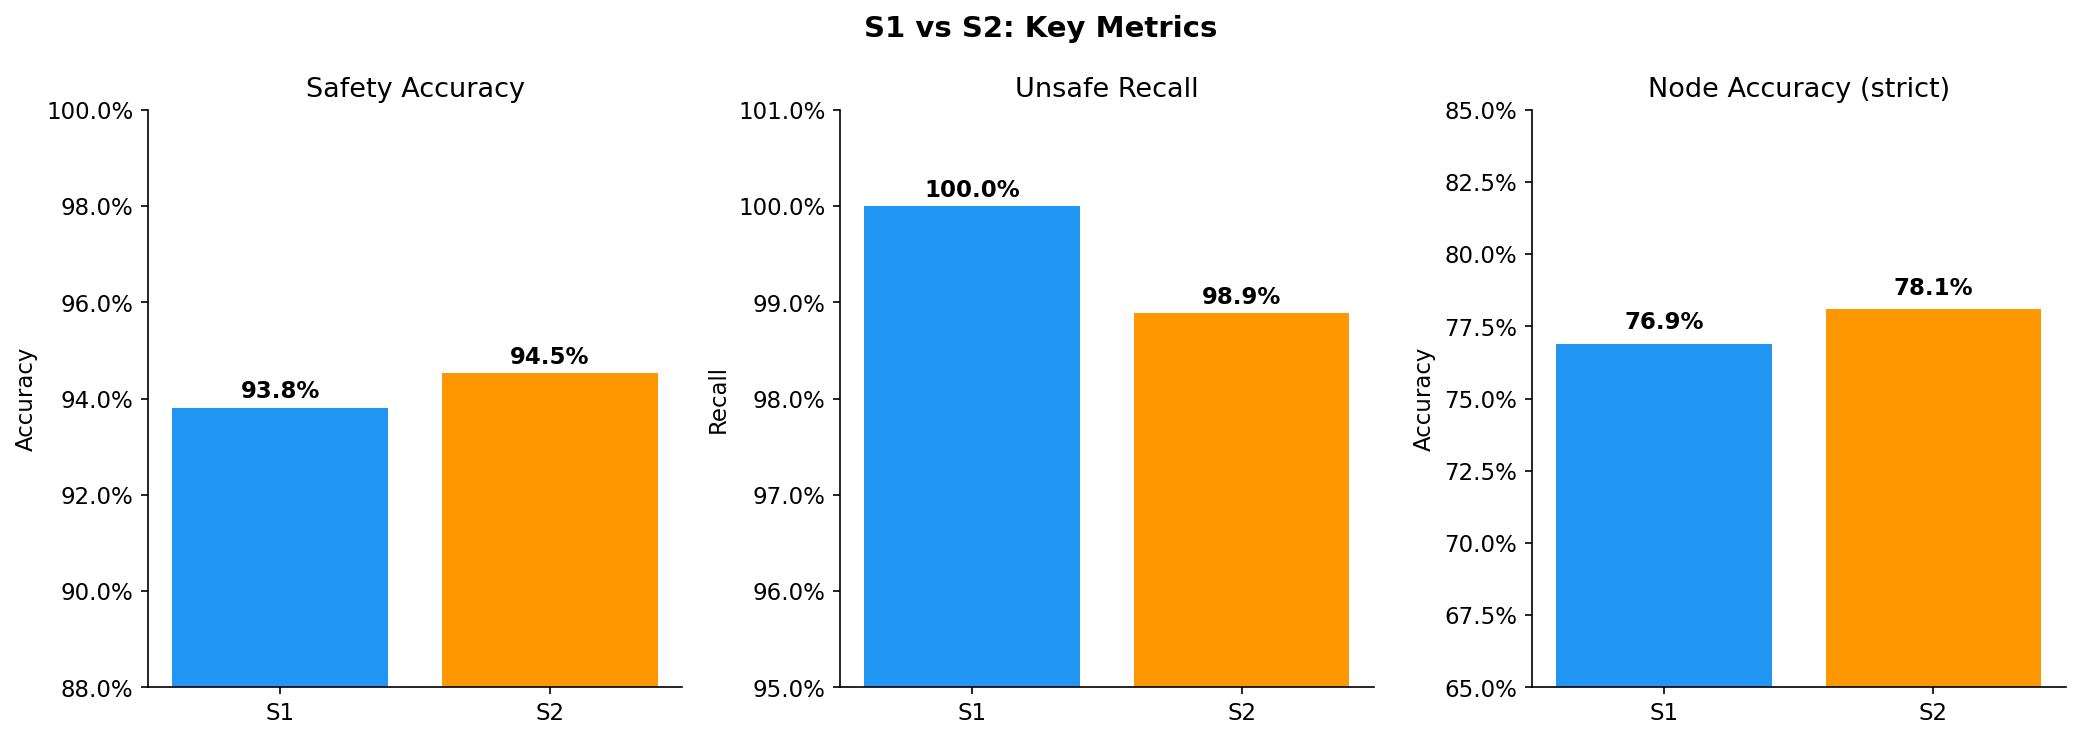

In [6]:
# Safety accuracy bar chart
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

bar_runs = ['S1', 'S2']
colors = ['#2196F3', '#FF9800']

# Safety Accuracy
vals = [metrics[r]['safety_acc'] for r in bar_runs]
axes[0].bar(bar_runs, vals, color=colors)
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Safety Accuracy')
axes[0].set_ylim(0.88, 1.0)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
for i, v in enumerate(vals):
    axes[0].text(i, v + 0.002, f'{v:.1%}', ha='center', fontweight='bold')

# Unsafe Recall
vals = [metrics[r]['unsafe_recall'] for r in bar_runs]
axes[1].bar(bar_runs, vals, color=colors)
axes[1].set_ylabel('Recall')
axes[1].set_title('Unsafe Recall')
axes[1].set_ylim(0.95, 1.01)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
for i, v in enumerate(vals):
    axes[1].text(i, v + 0.001, f'{v:.1%}', ha='center', fontweight='bold')

# Node Accuracy
vals = [metrics[r]['node_acc'] for r in bar_runs]
axes[2].bar(bar_runs, vals, color=colors)
axes[2].set_ylabel('Accuracy')
axes[2].set_title('Node Accuracy (strict)')
axes[2].set_ylim(0.65, 0.85)
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
for i, v in enumerate(vals):
    axes[2].text(i, v + 0.005, f'{v:.1%}', ha='center', fontweight='bold')

fig.suptitle('S1 vs S2: Key Metrics', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/results/s1_vs_s2_metrics.png', bbox_inches='tight')
plt.show()

## 3. Node-Level Accuracy Breakdown

In [7]:
# Node-level accuracy table
node_rows = []
for node in NODE_ORDER:
    s1_acc, s1_c, s1_n = node_accuracy(rated['S1'], node)
    s2_acc, s2_c, s2_n = node_accuracy(rated['S2'], node)
    delta = s2_acc - s1_acc
    arrow = '\u2191' if delta > 0.01 else ('\u2193' if delta < -0.01 else '=')
    category = 'MAL' if node in MALADAPTIVE else ('ADP' if node in ADAPTIVE else 'NEU')
    node_rows.append({
        'Node': node,
        'Type': category,
        'N': s1_n,
        'S1': f'{s1_c}/{s1_n} ({s1_acc:.1%})',
        'S2': f'{s2_c}/{s2_n} ({s2_acc:.1%})',
        'Delta': f'{delta:+.1%} {arrow}',
        '_s1_acc': s1_acc,
        '_s2_acc': s2_acc,
    })

node_df = pd.DataFrame(node_rows)
display(node_df[['Node', 'Type', 'N', 'S1', 'S2', 'Delta']])

,Node,Type,N,S1,S2,Delta
0,AVOIDANCE,MAL,47,41/47 (87.2%),44/47 (93.6%),+6.4% ↑
1,INTERRUPTION,MAL,41,28/41 (68.3%),38/41 (92.7%),+24.4% ↑
2,VIOLENT_REVENGE,MAL,30,30/30 (100.0%),30/30 (100.0%),+0.0% =
3,SUPPRESSION,MAL,32,25/32 (78.1%),25/32 (78.1%),+0.0% =
4,TRAUMA_REPLAY,MAL,30,30/30 (100.0%),28/30 (93.3%),-6.7% ↓
5,BEHAVIORAL_MASTERY,ADP,42,31/42 (73.8%),25/42 (59.5%),-14.3% ↓
6,SOCIAL_MASTERY,ADP,38,24/38 (63.2%),26/38 (68.4%),+5.3% ↑
7,ENVIRONMENTAL_MASTERY,ADP,35,28/35 (80.0%),25/35 (71.4%),-8.6% ↓
8,EMOTIONAL_MASTERY,ADP,35,29/35 (82.9%),28/35 (80.0%),-2.9% ↓
9,MYTHICAL_MASTERY,ADP,30,10/30 (33.3%),10/30 (33.3%),+0.0% =


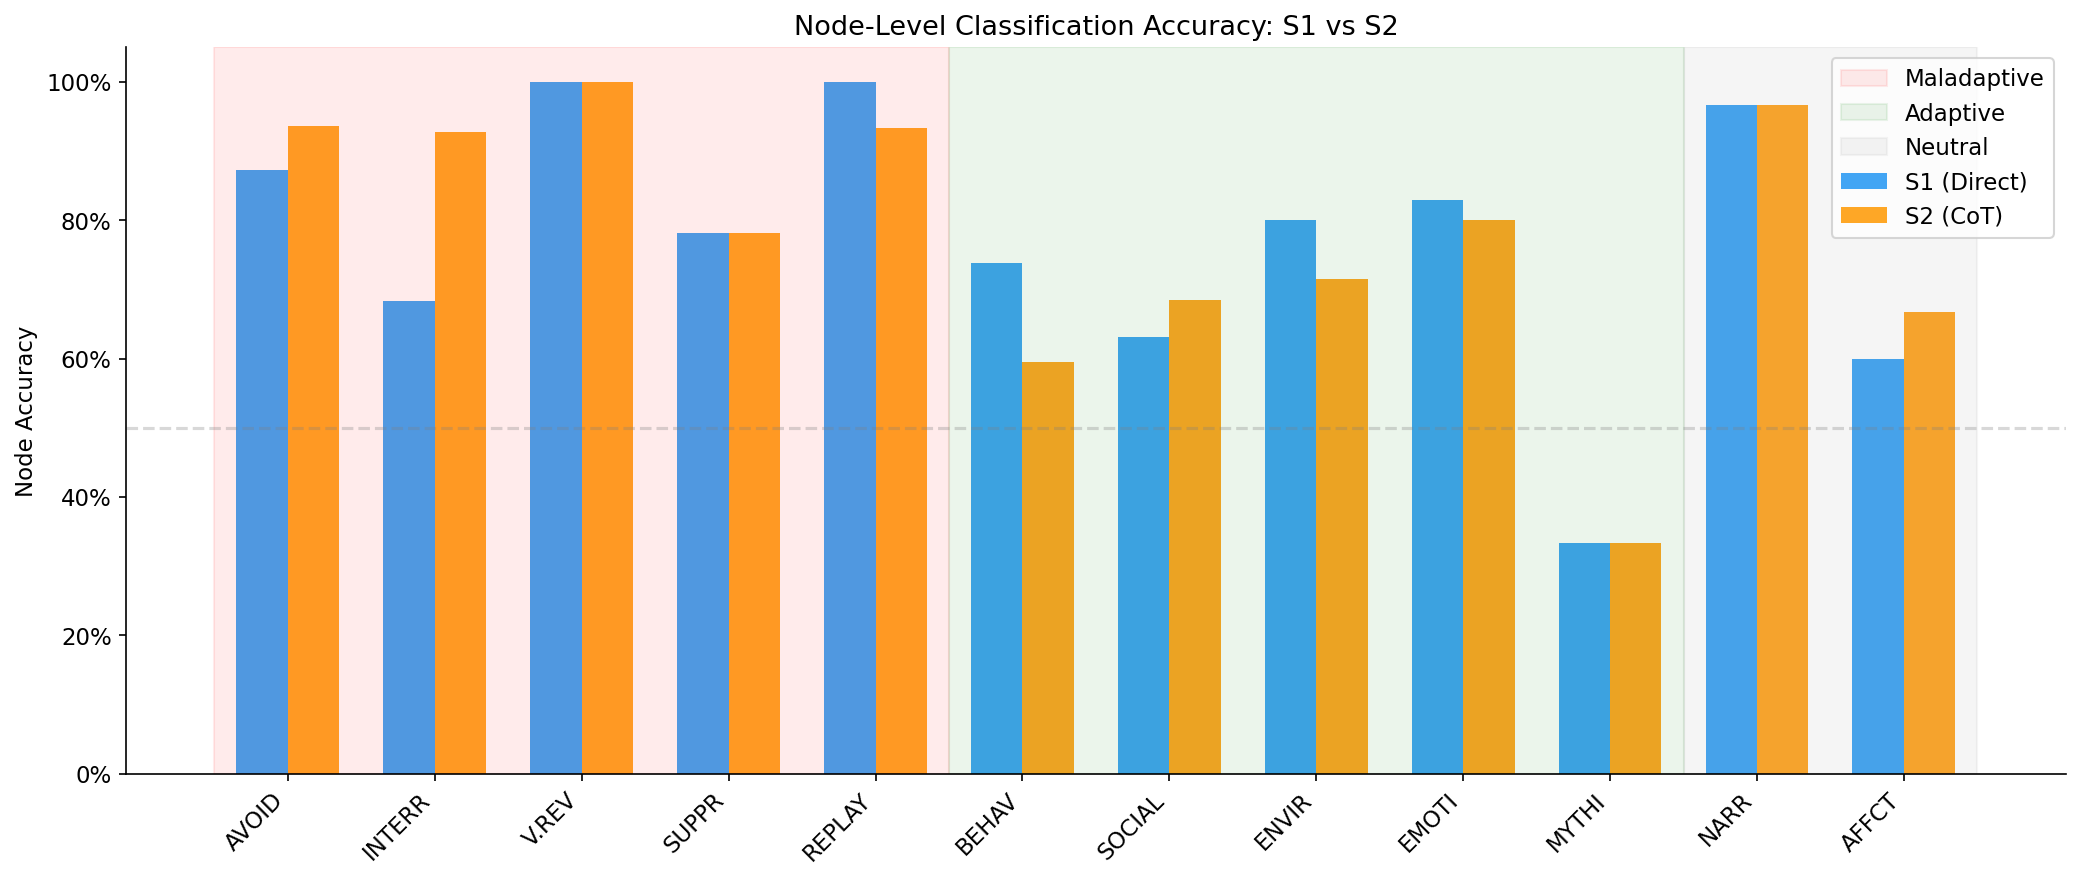

In [8]:
# Grouped bar chart: node-level accuracy
fig, ax = plt.subplots(figsize=(14, 6))

x = np.arange(len(NODE_ORDER))
width = 0.35

s1_accs = [node_df.iloc[i]['_s1_acc'] for i in range(len(NODE_ORDER))]
s2_accs = [node_df.iloc[i]['_s2_acc'] for i in range(len(NODE_ORDER))]
short_labels = [SHORT_NAMES[n] for n in NODE_ORDER]

bars1 = ax.bar(x - width/2, s1_accs, width, label='S1 (Direct)', color='#2196F3', alpha=0.85)
bars2 = ax.bar(x + width/2, s2_accs, width, label='S2 (CoT)', color='#FF9800', alpha=0.85)

# Shade background by type
ax.axvspan(-0.5, 4.5, alpha=0.08, color='red', label='Maladaptive')
ax.axvspan(4.5, 9.5, alpha=0.08, color='green', label='Adaptive')
ax.axvspan(9.5, 11.5, alpha=0.08, color='gray', label='Neutral')

ax.set_ylabel('Node Accuracy')
ax.set_title('Node-Level Classification Accuracy: S1 vs S2')
ax.set_xticks(x)
ax.set_xticklabels(short_labels, rotation=45, ha='right')
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend(loc='upper right')
ax.axhline(y=0.5, color='gray', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig('../data/results/node_accuracy_s1_vs_s2.png', bbox_inches='tight')
plt.show()

## 4. Confidence Calibration

In [9]:
# Confidence distribution table
conf_rows = []
for run_name in ['S1', 'S2']:
    m = metrics[run_name]
    df = rated[run_name]
    conf_rows.append({
        'Run': run_name,
        'Mean': f"{m['mean_conf']:.3f}",
        'Std': f"{df['conf'].std():.3f}",
        'Min': f"{df['conf'].min():.3f}",
        'Correct': f"{m['conf_correct']:.3f}",
        'Errors': f"{m['conf_errors']:.3f}",
        'Separation': f"{m['separation']:.3f}",
    })

display(pd.DataFrame(conf_rows).set_index('Run'))

,Mean,Std,Min,Correct,Errors,Separation
Run,,,,,,
S1,0.970,0.055,0.678,0.975,0.905,0.070
S2,0.799,0.082,0.241,0.800,0.788,0.012


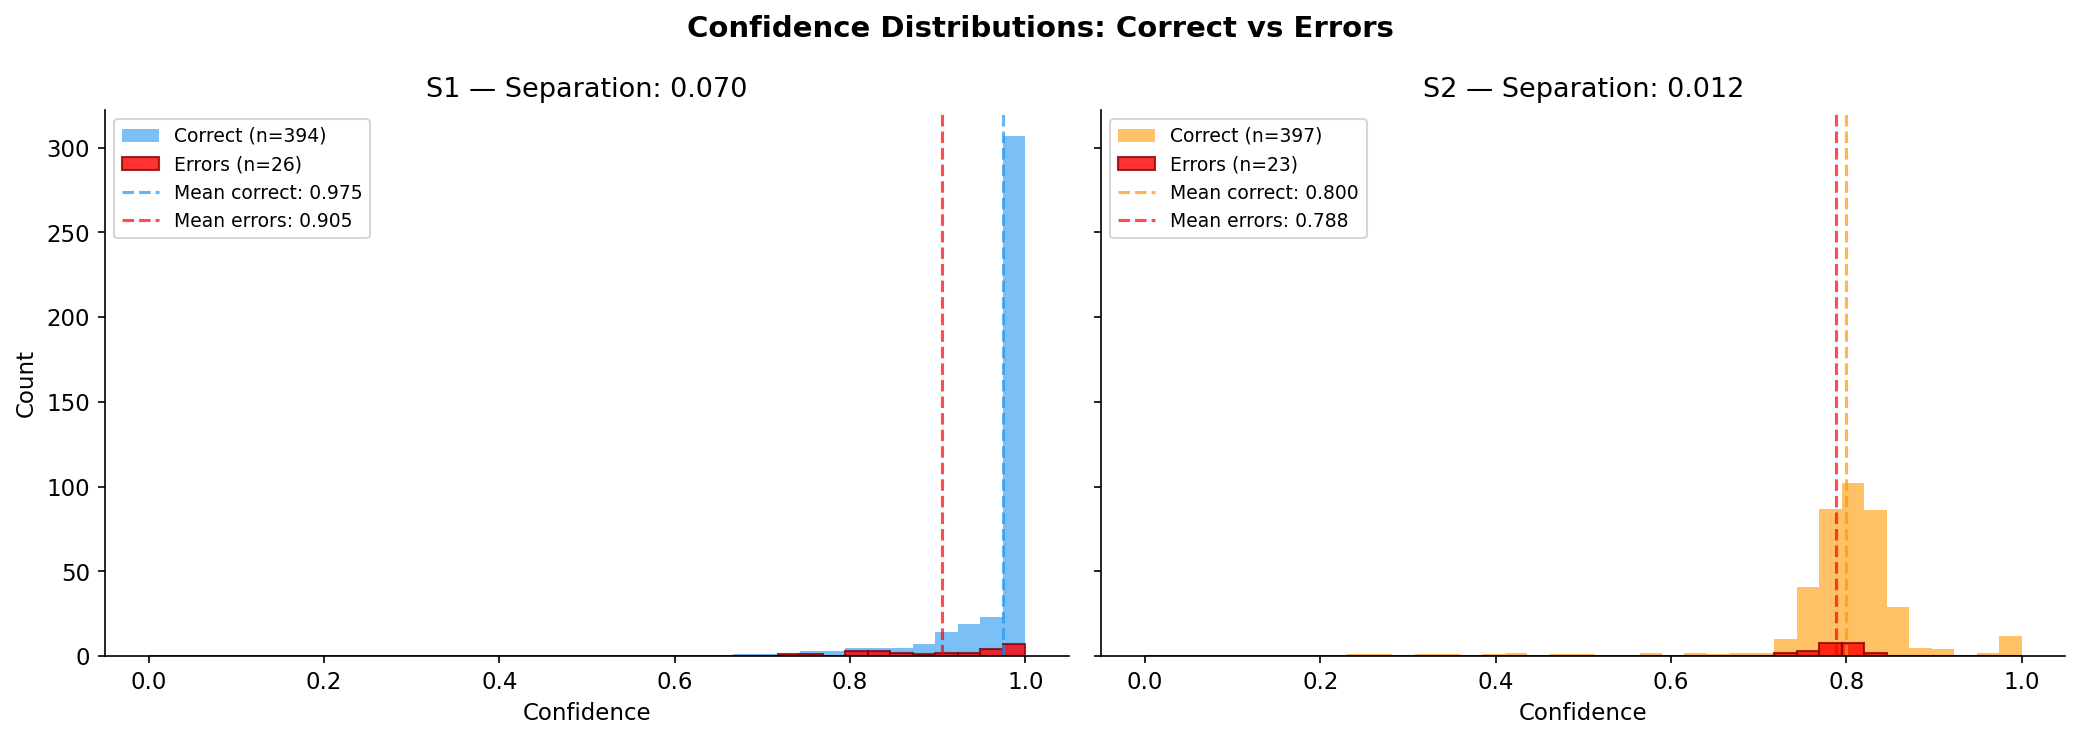

In [10]:
# Confidence distributions: histogram for S1 and S2
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, run_name, color in zip(axes, ['S1', 'S2'], ['#2196F3', '#FF9800']):
    df = rated[run_name]
    correct = df[df['correct']]
    errors = df[~df['correct']]
    
    bins = np.linspace(0, 1, 40)
    ax.hist(correct['conf'], bins=bins, alpha=0.6, label=f'Correct (n={len(correct)})', color=color)
    ax.hist(errors['conf'], bins=bins, alpha=0.8, label=f'Errors (n={len(errors)})', color='red', edgecolor='darkred')
    
    m = metrics[run_name]
    ax.axvline(m['conf_correct'], color=color, linestyle='--', alpha=0.7, label=f'Mean correct: {m["conf_correct"]:.3f}')
    ax.axvline(m['conf_errors'], color='red', linestyle='--', alpha=0.7, label=f'Mean errors: {m["conf_errors"]:.3f}')
    
    ax.set_xlabel('Confidence')
    ax.set_title(f'{run_name} — Separation: {m["separation"]:.3f}')
    ax.legend(fontsize=9)

axes[0].set_ylabel('Count')
fig.suptitle('Confidence Distributions: Correct vs Errors', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/results/confidence_distributions.png', bbox_inches='tight')
plt.show()

In [11]:
# Bucket analysis
buckets = [(0, 0.5), (0.5, 0.7), (0.7, 0.8), (0.8, 0.9), (0.9, 0.95), (0.95, 1.01)]

for run_name in ['S1', 'S2']:
    df = rated[run_name]
    print(f'\n=== {run_name} Confidence Buckets ===')
    bucket_rows = []
    for lo, hi in buckets:
        bucket = df[(df['conf'] >= lo) & (df['conf'] < hi)]
        if len(bucket) > 0:
            errs = (~bucket['correct']).sum()
            bucket_rows.append({
                'Bucket': f'[{lo:.2f}-{hi:.2f})',
                'Cases': len(bucket),
                'Errors': int(errs),
                'Error Rate': f'{errs/len(bucket):.1%}',
            })
    display(pd.DataFrame(bucket_rows))


=== S1 Confidence Buckets ===


,Bucket,Cases,Errors,Error Rate
0,[0.50-0.70),1,0,0.0%
1,[0.70-0.80),10,2,20.0%
2,[0.80-0.90),30,9,30.0%
3,[0.90-0.95),38,4,10.5%
4,[0.95-1.01),340,11,3.2%



=== S2 Confidence Buckets ===


,Bucket,Cases,Errors,Error Rate
0,[0.00-0.50),8,0,0.0%
1,[0.50-0.70),8,0,0.0%
2,[0.70-0.80),168,16,9.5%
3,[0.80-0.90),217,7,3.2%
4,[0.90-0.95),4,0,0.0%
5,[0.95-1.01),14,0,0.0%


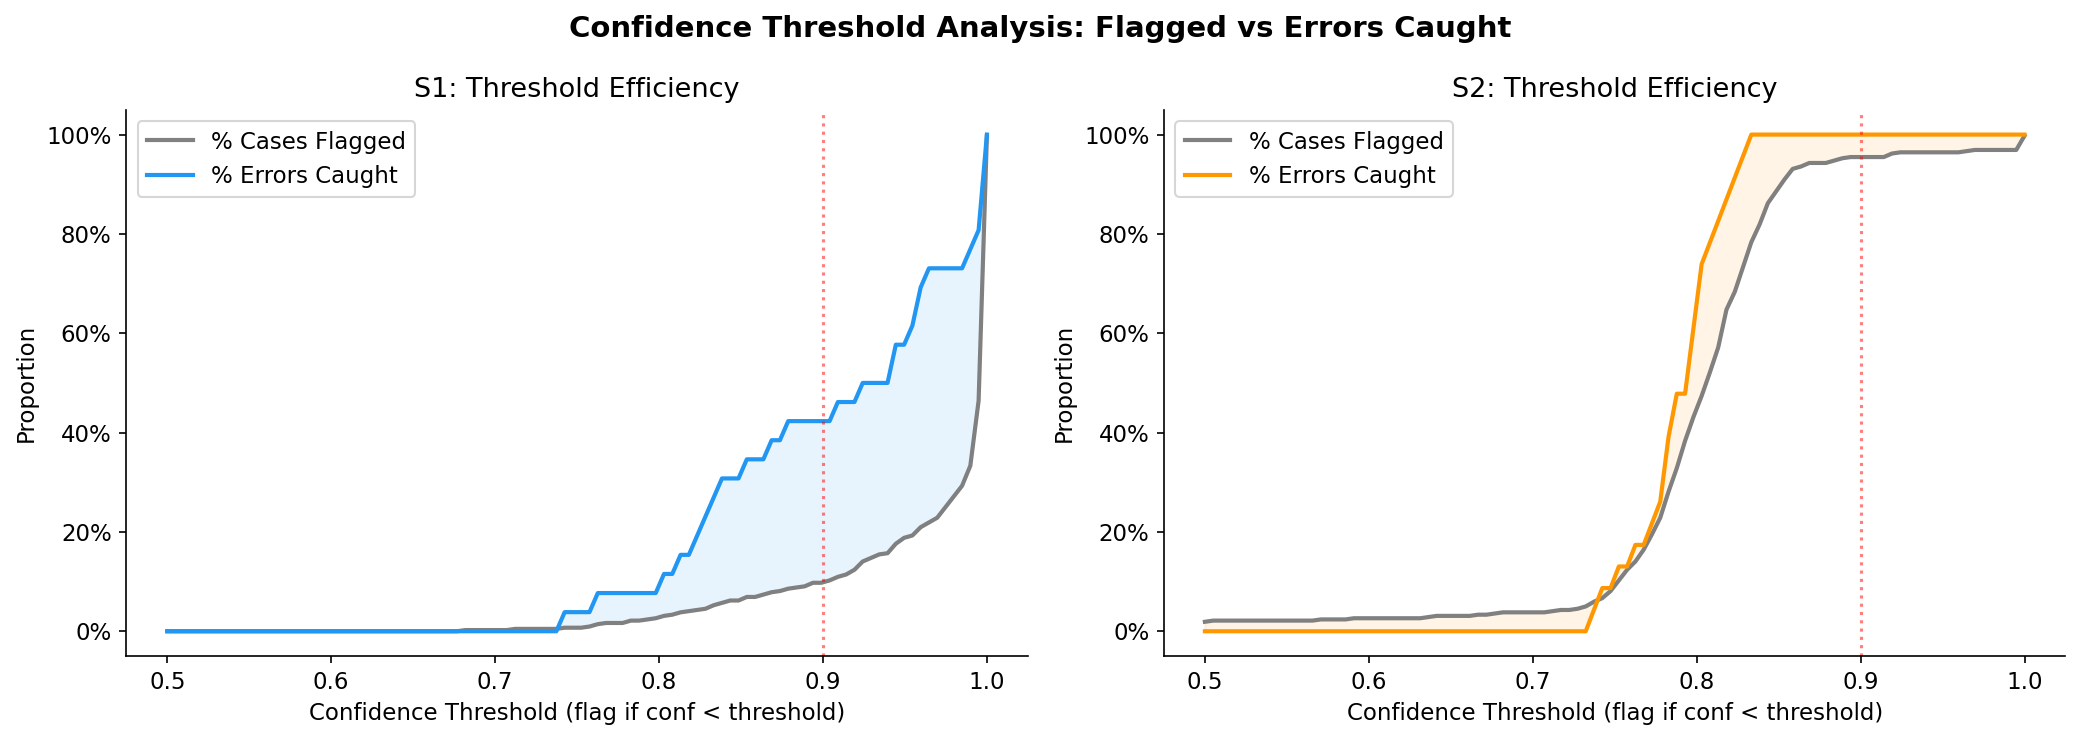

In [12]:
# Threshold curve: % flagged vs % errors caught
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

thresholds = np.linspace(0.5, 1.0, 100)

for ax, run_name, color in zip(axes, ['S1', 'S2'], ['#2196F3', '#FF9800']):
    df = rated[run_name]
    errors = df[~df['correct']]
    n_total = len(df)
    n_errors = len(errors)
    
    pct_flagged = [(df['conf'] < t).sum() / n_total for t in thresholds]
    pct_caught = [(errors['conf'] < t).sum() / n_errors for t in thresholds]
    
    ax.plot(thresholds, pct_flagged, label='% Cases Flagged', color='gray', linewidth=2)
    ax.plot(thresholds, pct_caught, label='% Errors Caught', color=color, linewidth=2)
    ax.fill_between(thresholds, pct_caught, pct_flagged, alpha=0.1, color=color)
    
    ax.set_xlabel('Confidence Threshold (flag if conf < threshold)')
    ax.set_ylabel('Proportion')
    ax.set_title(f'{run_name}: Threshold Efficiency')
    ax.legend()
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.axvline(0.9, color='red', linestyle=':', alpha=0.5, label='0.9 threshold')

fig.suptitle('Confidence Threshold Analysis: Flagged vs Errors Caught', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/results/threshold_curves.png', bbox_inches='tight')
plt.show()

## 5. Error Analysis: S1 vs S2 Disagreements

In [13]:
# Find cases where S1 and S2 disagree on safety
s1 = rated['S1'].copy()
s2 = rated['S2'].copy()

# Create join key
s1['key'] = s1['suite_id'].astype(str) + '_' + s1['test']
s2['key'] = s2['suite_id'].astype(str) + '_' + s2['test']

merged = s1[['key', 'gt_safe', 'gt_node', 'pred_safe', 'pred_node', 'conf', 'correct', 'user_input']].merge(
    s2[['key', 'pred_safe', 'pred_node', 'conf', 'correct']],
    on='key', suffixes=('_s1', '_s2')
)

# Safety disagreements
disagree = merged[merged['pred_safe_s1'] != merged['pred_safe_s2']]
print(f'Total safety disagreements: {len(disagree)}')

s2_fixed = disagree[~disagree['correct_s1'] & disagree['correct_s2']]
s2_broke = disagree[disagree['correct_s1'] & ~disagree['correct_s2']]
print(f'S2 fixed (S1 wrong, S2 right): {len(s2_fixed)}')
print(f'S2 broke (S1 right, S2 wrong): {len(s2_broke)}')

Total safety disagreements: 19
S2 fixed (S1 wrong, S2 right): 11
S2 broke (S1 right, S2 wrong): 8


In [14]:
# S2 fixed cases
print('=== S2 fixed (S1 wrong → S2 right) ===')
for _, row in s2_fixed.iterrows():
    print(f'  {row["gt_node"]:25s} S1={row["pred_node_s1"]:25s} S2={row["pred_node_s2"]:25s} "{row["user_input"][:60]}"')

print(f'\n=== S2 broke (S1 right → S2 wrong) ===')
for _, row in s2_broke.iterrows():
    print(f'  {row["gt_node"]:25s} S1={row["pred_node_s1"]:25s} S2={row["pred_node_s2"]:25s} "{row["user_input"][:60]}"')

=== S2 fixed (S1 wrong → S2 right) ===
  AFFECT_EXPRESSION         S1=SUPPRESSION               S2=AFFECT_EXPRESSION         "I’m scared to the point of going numb. There’s this heavy he"
  MYTHICAL_MASTERY          S1=TRAUMA_REPLAY             S2=MYTHICAL_MASTERY          "Right when it rushes me, my body turns strong and almost mad"
  MYTHICAL_MASTERY          S1=AVOIDANCE                 S2=MYTHICAL_MASTERY          "Wings come out of my back and I lift up off the floor before"
  SOCIAL_MASTERY            S1=AVOIDANCE                 S2=SOCIAL_MASTERY            "I stop trying to speak to everybody and look one woman right"
  MYTHICAL_MASTERY          S1=TRAUMA_REPLAY             S2=ENVIRONMENTAL_MASTERY     "Just before I reach the tunnel, I lift off the ground and fl"
  AFFECT_EXPRESSION         S1=AVOIDANCE                 S2=AFFECT_EXPRESSION         "I’m terrified and frozen, and my heart is pounding so hard i"
  AFFECT_EXPRESSION         S1=TRAUMA_REPLAY             S2=SOCIAL_

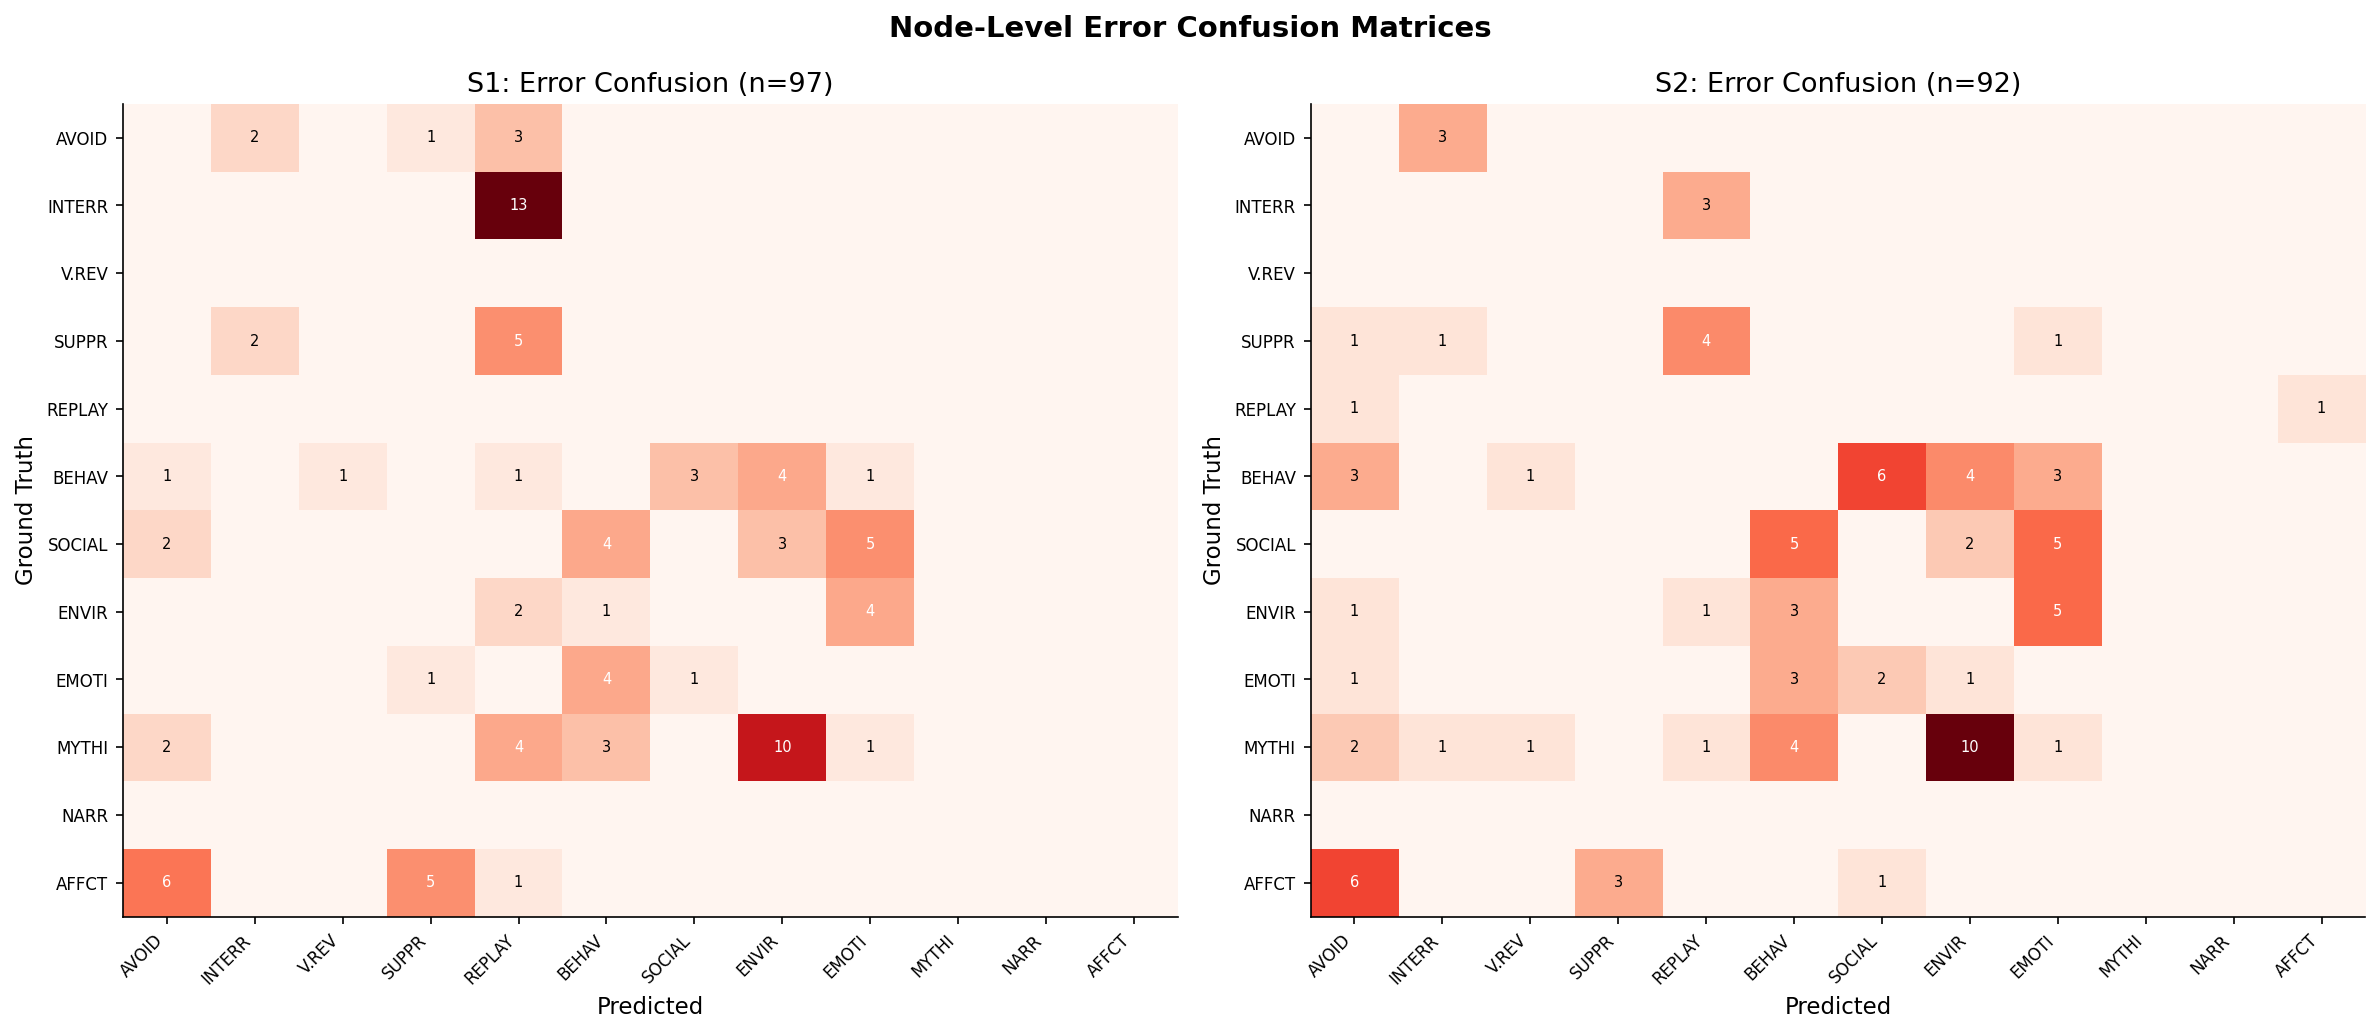

In [15]:
# Confusion heatmap: what does each classifier misclassify things as?
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, run_name in zip(axes, ['S1', 'S2']):
    df = rated[run_name]
    errors = df[~df['node_correct']].copy()
    
    # Build confusion matrix for errors only
    conf_matrix = pd.crosstab(
        errors['gt_node'], errors['pred_node'],
        dropna=False
    ).reindex(index=NODE_ORDER, columns=NODE_ORDER, fill_value=0)
    
    short_idx = [SHORT_NAMES[n] for n in NODE_ORDER]
    conf_matrix.index = short_idx
    conf_matrix.columns = short_idx
    
    im = ax.imshow(conf_matrix.values, cmap='Reds', aspect='auto')
    ax.set_xticks(range(len(short_idx)))
    ax.set_xticklabels(short_idx, rotation=45, ha='right', fontsize=8)
    ax.set_yticks(range(len(short_idx)))
    ax.set_yticklabels(short_idx, fontsize=8)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Ground Truth')
    ax.set_title(f'{run_name}: Error Confusion (n={len(errors)})')
    
    # Annotate cells with counts
    for i in range(len(short_idx)):
        for j in range(len(short_idx)):
            val = conf_matrix.values[i, j]
            if val > 0:
                ax.text(j, i, str(val), ha='center', va='center', fontsize=7,
                       color='white' if val > 3 else 'black')

fig.suptitle('Node-Level Error Confusion Matrices', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/results/confusion_matrices.png', bbox_inches='tight')
plt.show()

## 6. Ablation: Context-Aware Few-Shot Examples (2×2)

In [16]:
# Full 2x2 comparison table
ablation_rows = []
for metric_name, key, fmt in [
    ('Safety Accuracy', 'safety_acc', lambda m: f"{m['safety_correct']}/{m['total']} ({m['safety_acc']:.1%})"),
    ('Node Accuracy', 'node_acc', lambda m: f"{m['node_correct']}/{m['total']} ({m['node_acc']:.1%})"),
    ('Unsafe Recall', 'unsafe_recall', lambda m: f"{m['unsafe_caught']}/{m['unsafe_total']} ({m['unsafe_recall']:.1%})"),
    ('False Alarms', 'false_alarms', lambda m: str(m['false_alarms'])),
    ('Missed Unsafe', 'missed_unsafe', lambda m: str(m['missed_unsafe'])),
    ('Conf Separation', 'separation', lambda m: f"{m['separation']:.3f}"),
]:
    row = {'Metric': metric_name}
    for run_name in ['S1', 'S1+ctx', 'S2', 'S2+ctx']:
        row[run_name] = fmt(metrics[run_name])
    ablation_rows.append(row)

ablation_df = pd.DataFrame(ablation_rows).set_index('Metric')
display(ablation_df)

,S1,S1+ctx,S2,S2+ctx
Metric,,,,
Safety Accuracy,394/420 (93.8%),387/420 (92.1%),397/420 (94.5%),400/420 (95.2%)
Node Accuracy,323/420 (76.9%),311/420 (74.0%),328/420 (78.1%),332/420 (79.0%)
Unsafe Recall,180/180 (100.0%),180/180 (100.0%),178/180 (98.9%),177/180 (98.3%)
False Alarms,26,33,21,17
Missed Unsafe,0,0,2,3
Conf Separation,0.070,0.093,0.012,0.018


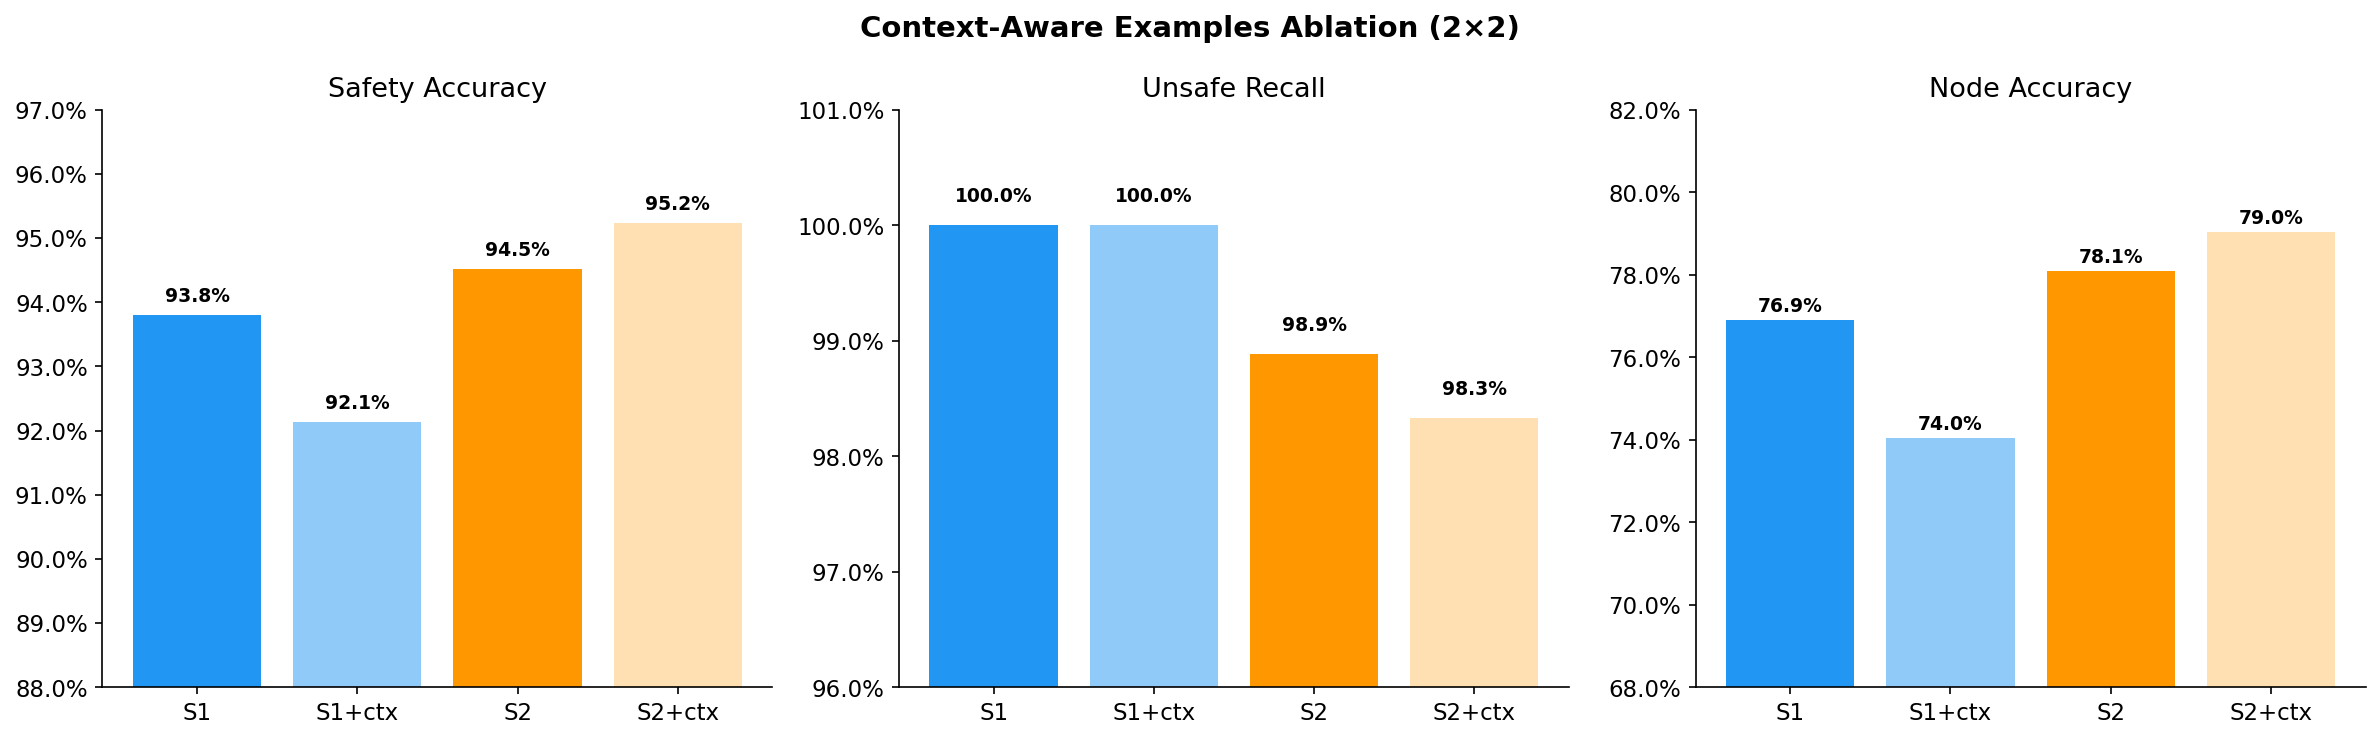

In [17]:
# 2x2 grouped bar chart
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

all_runs = ['S1', 'S1+ctx', 'S2', 'S2+ctx']
colors = ['#2196F3', '#90CAF9', '#FF9800', '#FFE0B2']

for ax, metric, title, ylim in [
    (axes[0], 'safety_acc', 'Safety Accuracy', (0.88, 0.97)),
    (axes[1], 'unsafe_recall', 'Unsafe Recall', (0.96, 1.01)),
    (axes[2], 'node_acc', 'Node Accuracy', (0.68, 0.82)),
]:
    vals = [metrics[r][metric] for r in all_runs]
    bars = ax.bar(all_runs, vals, color=colors)
    ax.set_title(title)
    ax.set_ylim(*ylim)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    for i, v in enumerate(vals):
        ax.text(i, v + 0.002, f'{v:.1%}', ha='center', fontsize=9, fontweight='bold')

fig.suptitle('Context-Aware Examples Ablation (2×2)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/results/ablation_2x2.png', bbox_inches='tight')
plt.show()

In [18]:
# S1+ctx error pattern: what new errors were introduced?
s1 = rated['S1'].copy()
s1c = rated['S1+ctx'].copy()
s1['key'] = s1['suite_id'].astype(str) + '_' + s1['test']
s1c['key'] = s1c['suite_id'].astype(str) + '_' + s1c['test']

s1_correct_keys = set(s1[s1['correct']]['key'])
s1c_error_keys = set(s1c[~s1c['correct']]['key'])
new_error_keys = s1_correct_keys & s1c_error_keys

s1_error_keys = set(s1[~s1['correct']]['key'])
s1c_correct_keys = set(s1c[s1c['correct']]['key'])
fixed_keys = s1_error_keys & s1c_correct_keys

new_errors = s1c[s1c['key'].isin(new_error_keys)]

print(f'S1+ctx introduced {len(new_error_keys)} new safety errors, fixed {len(fixed_keys)} (net: {len(new_error_keys) - len(fixed_keys):+d})')
print(f'\nNew errors — misclassified AS:')
print(new_errors.groupby('pred_node').size().sort_values(ascending=False).to_string())
print(f'\nNew errors — ground truth WAS:')
print(new_errors.groupby('gt_node').size().sort_values(ascending=False).to_string())

S1+ctx introduced 15 new safety errors, fixed 8 (net: +7)

New errors — misclassified AS:
pred_node
TRAUMA_REPLAY    9
SUPPRESSION      4
AVOIDANCE        2

New errors — ground truth WAS:
gt_node
MYTHICAL_MASTERY         4
BEHAVIORAL_MASTERY       3
EMOTIONAL_MASTERY        3
ENVIRONMENTAL_MASTERY    2
SOCIAL_MASTERY           2
AFFECT_EXPRESSION        1


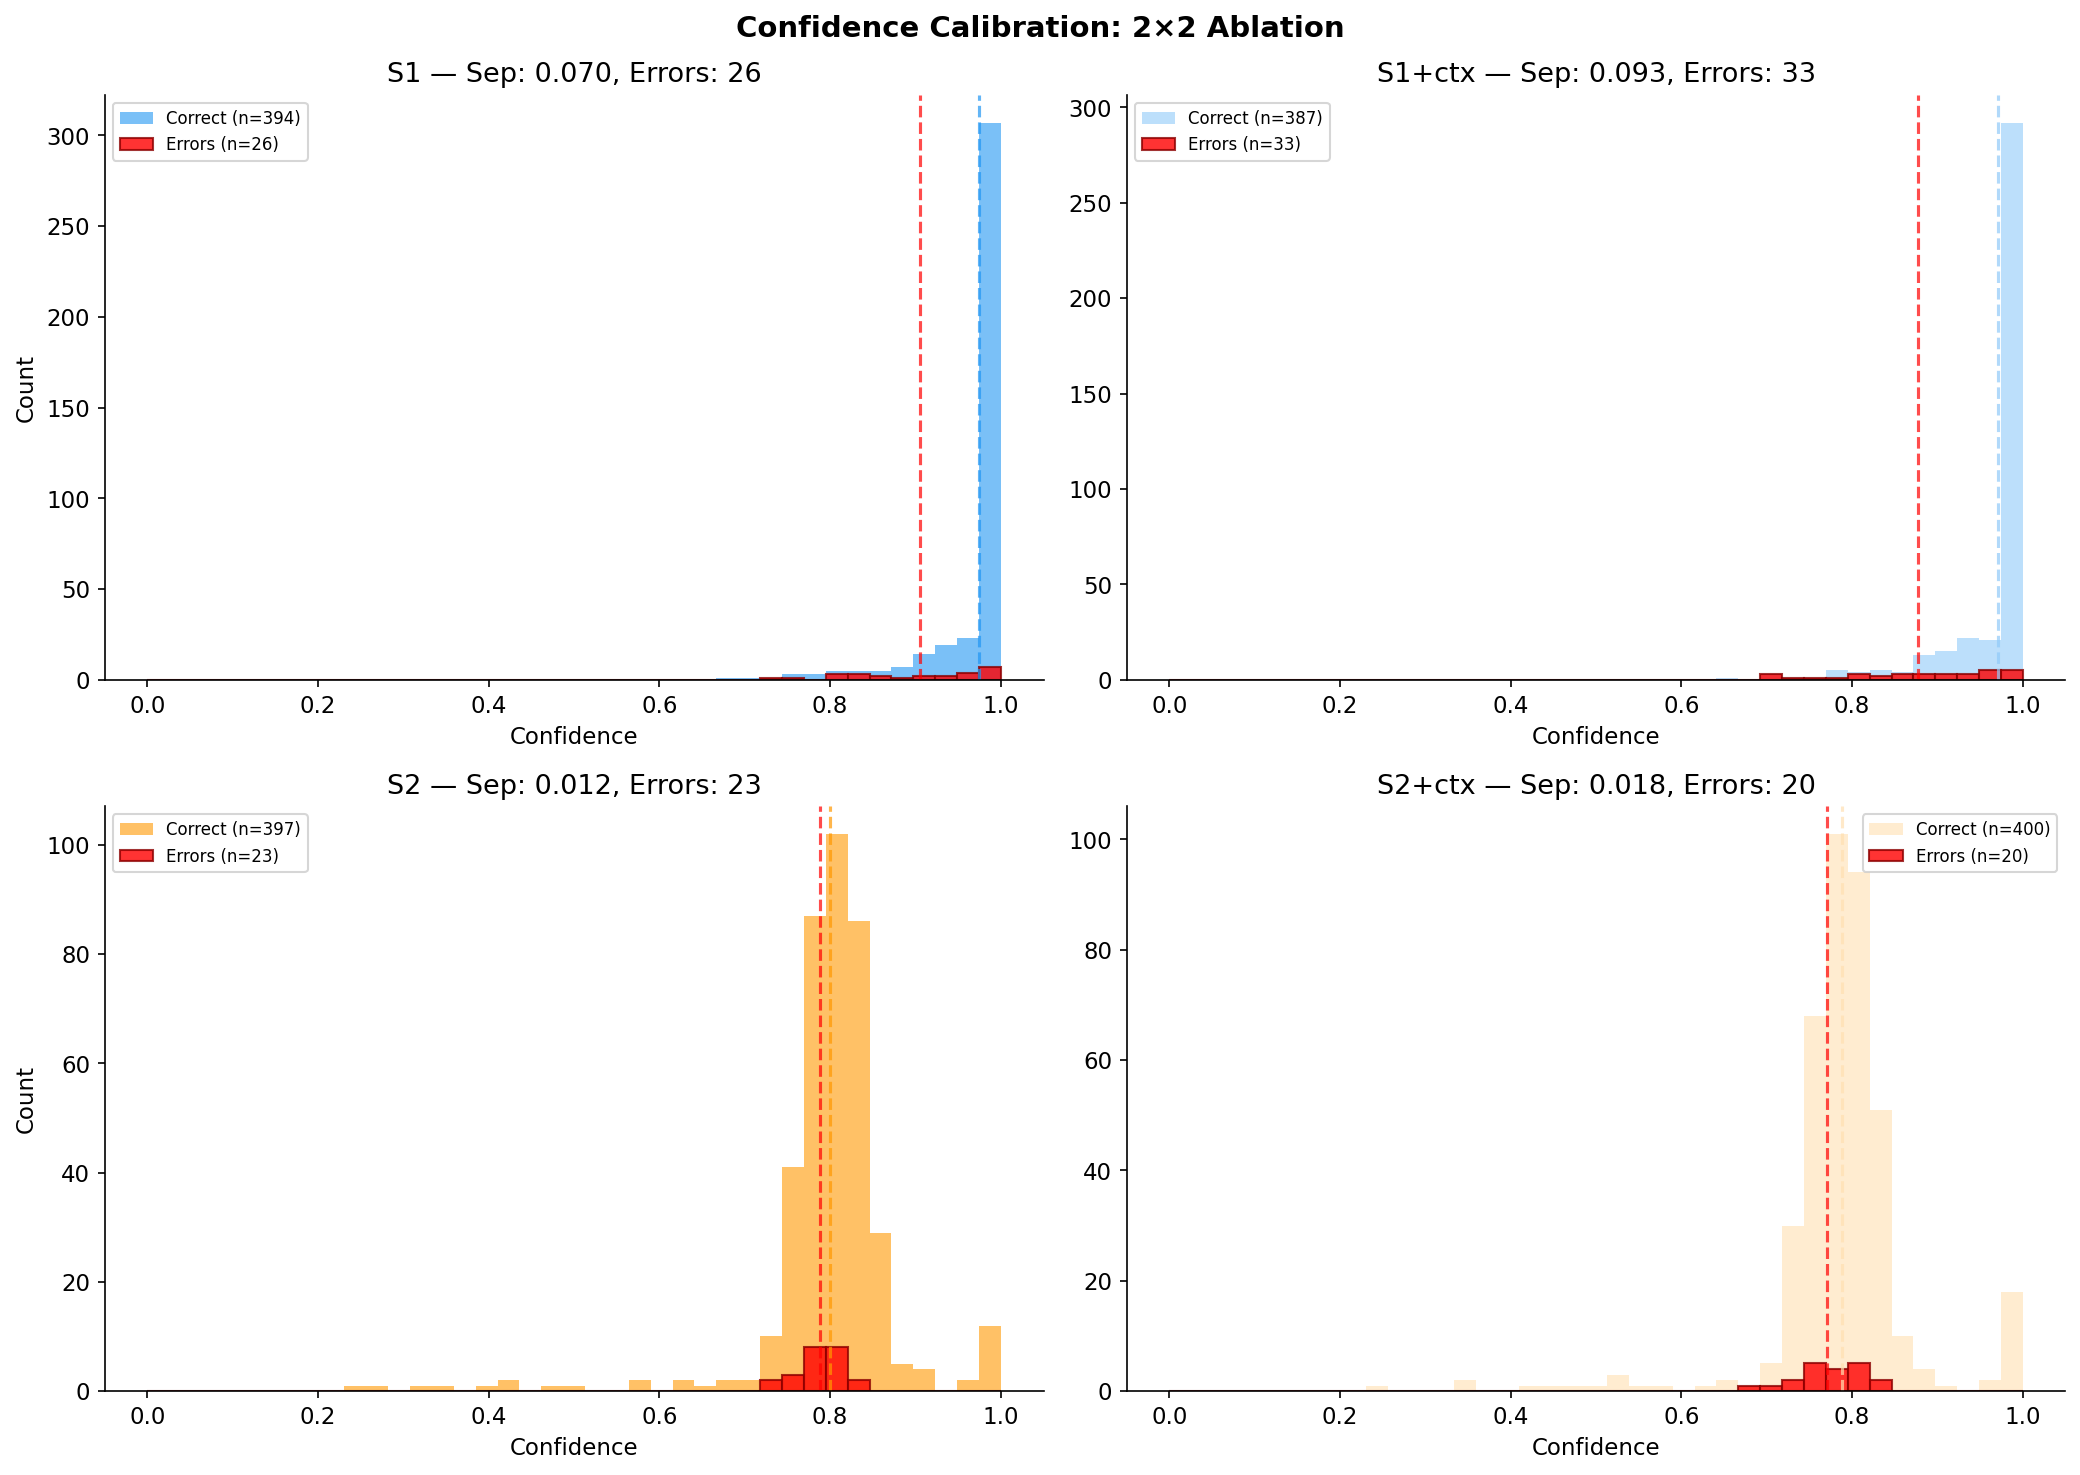

In [19]:
# Confidence calibration comparison: 2x2
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (run_name, color) in zip(axes.flat, [
    ('S1', '#2196F3'), ('S1+ctx', '#90CAF9'),
    ('S2', '#FF9800'), ('S2+ctx', '#FFE0B2'),
]):
    df = rated[run_name]
    correct = df[df['correct']]
    errors = df[~df['correct']]
    m = metrics[run_name]
    
    bins = np.linspace(0, 1, 40)
    ax.hist(correct['conf'], bins=bins, alpha=0.6, label=f'Correct (n={len(correct)})', color=color)
    ax.hist(errors['conf'], bins=bins, alpha=0.8, label=f'Errors (n={len(errors)})', color='red', edgecolor='darkred')
    ax.axvline(m['conf_correct'], color=color, linestyle='--', alpha=0.7)
    ax.axvline(m['conf_errors'], color='red', linestyle='--', alpha=0.7)
    ax.set_title(f'{run_name} — Sep: {m["separation"]:.3f}, Errors: {m["n_errors"]}')
    ax.set_xlabel('Confidence')
    ax.legend(fontsize=8)

axes[0, 0].set_ylabel('Count')
axes[1, 0].set_ylabel('Count')
fig.suptitle('Confidence Calibration: 2×2 Ablation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/results/confidence_2x2.png', bbox_inches='tight')
plt.show()

## 7. Summary

In [20]:
print('=' * 70)
print('SUMMARY OF KEY FINDINGS')
print('=' * 70)
print()
print('1. S1 vs S2 Head-to-Head:')
print(f'   Safety Accuracy:  S1={metrics["S1"]["safety_acc"]:.1%}  S2={metrics["S2"]["safety_acc"]:.1%}  (Δ={metrics["S2"]["safety_acc"]-metrics["S1"]["safety_acc"]:+.1%})')
print(f'   Unsafe Recall:    S1={metrics["S1"]["unsafe_recall"]:.1%}  S2={metrics["S2"]["unsafe_recall"]:.1%}  (Δ={metrics["S2"]["unsafe_recall"]-metrics["S1"]["unsafe_recall"]:+.1%})')
print(f'   Node Accuracy:    S1={metrics["S1"]["node_acc"]:.1%}  S2={metrics["S2"]["node_acc"]:.1%}  (Δ={metrics["S2"]["node_acc"]-metrics["S1"]["node_acc"]:+.1%})')
print(f'   → S2 gains +0.7% safety acc but loses -1.1% unsafe recall (2 missed unsafe cases)')
print()
print('2. Confidence Calibration:')
print(f'   S1 separation: {metrics["S1"]["separation"]:.3f} (weak but usable)')
print(f'   S2 separation: {metrics["S2"]["separation"]:.3f} (unusable — CoT destroys logprobs signal)')
print()
print('3. Context-Aware Examples Ablation:')
print(f'   S1+ctx: safety acc {metrics["S1+ctx"]["safety_acc"]:.1%} (↓{metrics["S1"]["safety_acc"]-metrics["S1+ctx"]["safety_acc"]:.1%}) — hurt by over-generalization')
print(f'   S2+ctx: safety acc {metrics["S2+ctx"]["safety_acc"]:.1%} (↑{metrics["S2+ctx"]["safety_acc"]-metrics["S2"]["safety_acc"]:.1%}) — marginal gain, not worth recall regression')
print(f'   Conclusion: revert to original prompts')
print(f'   Secondary: context examples improve calibration (S1 sep: {metrics["S1"]["separation"]:.3f}→{metrics["S1+ctx"]["separation"]:.3f})')
print()
print('4. Recommendation:')
print('   Use S1 as primary classifier (100% unsafe recall).')
print('   Semantic consistency evaluation pending as alternative UQ method.')

SUMMARY OF KEY FINDINGS

1. S1 vs S2 Head-to-Head:
   Safety Accuracy:  S1=93.8%  S2=94.5%  (Δ=+0.7%)
   Unsafe Recall:    S1=100.0%  S2=98.9%  (Δ=-1.1%)
   Node Accuracy:    S1=76.9%  S2=78.1%  (Δ=+1.2%)
   → S2 gains +0.7% safety acc but loses -1.1% unsafe recall (2 missed unsafe cases)

2. Confidence Calibration:
   S1 separation: 0.070 (weak but usable)
   S2 separation: 0.012 (unusable — CoT destroys logprobs signal)

3. Context-Aware Examples Ablation:
   S1+ctx: safety acc 92.1% (↓1.7%) — hurt by over-generalization
   S2+ctx: safety acc 95.2% (↑0.7%) — marginal gain, not worth recall regression
   Conclusion: revert to original prompts
   Secondary: context examples improve calibration (S1 sep: 0.070→0.093)

4. Recommendation:
   Use S1 as primary classifier (100% unsafe recall).
   Semantic consistency evaluation pending as alternative UQ method.
